## Step 1 & 2: Import Required Libraries

In [ ]:
!pip install -q tensorflow matplotlib numpy scikit-learn

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.manifold import TSNE

print("TensorFlow version:", tf.__version__)
tf.random.set_seed(42)
np.random.seed(42)


TensorFlow version: 2.20.0


## Step 3 & 4: Load the MNIST Dataset and Normalize Pixel Values

The MNIST dataset is loaded directly from `tensorflow.keras.datasets`, so **no manual dataset download/link is required**. Pixel values are scaled from the range [0, 255] to [0, 1].

Train shape: (60000, 784)
Test shape : (10000, 784)


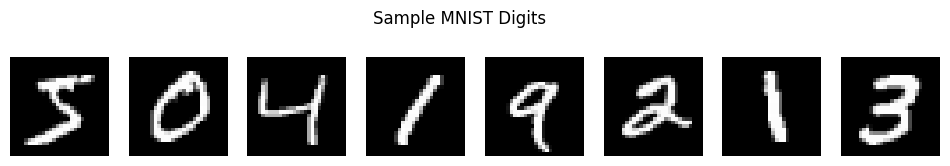

In [ ]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Normalize pixel values to [0, 1]
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Flatten 28x28 images into 784-dim vectors
image_size = x_train.shape[1] * x_train.shape[2]
x_train_flat = x_train.reshape((-1, image_size))
x_test_flat = x_test.reshape((-1, image_size))

print("Train shape:", x_train_flat.shape)
print("Test shape :", x_test_flat.shape)

# Show a few sample digits
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for i, ax in enumerate(axes):
    ax.imshow(x_train[i], cmap="gray")
    ax.axis("off")
plt.suptitle("Sample MNIST Digits")
plt.show()


## Step 5 & 6: Encoder Network and Reparameterization (Sampling) Layer

The encoder compresses each input image into a latent mean (`z_mean`) and log-variance (`z_log_var`).
The **Reparameterization Trick** samples a latent vector `z = mean + sigma * epsilon`, where `epsilon ~ N(0, 1)`, keeping the sampling step differentiable so gradients can flow during backpropagation.

In [ ]:
latent_dim = 2  # 2D latent space, chosen so it can be visualized directly on a scatter plot

# ---- Encoder ----
encoder_inputs = keras.Input(shape=(image_size,), name="encoder_input")
x = layers.Dense(256, activation="relu")(encoder_inputs)
x = layers.Dense(64, activation="relu")(x)

z_mean = layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)

class Sampling(layers.Layer):
    """Reparameterization trick: z = mean + std * epsilon"""
    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        epsilon = tf.random.normal(shape=(batch, dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

z = Sampling(name="z")([z_mean, z_log_var])

encoder = keras.Model(encoder_inputs, [z_mean, z_log_var, z], name="encoder")
encoder.summary()


Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 784)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 256)       │    200,960 │ encoder_input[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 64)        │     16,448 │ dense_10[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │        130 │ dense_11[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │        130 │ dense_11[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z (Sampling)        │ (None, 2)         │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 217,668 (850.27 KB)

 Trainable params: 217,668 (850.27 KB)

 Non-trainable params: 0 (0.00 B)

## Step 7: Decoder Network

In [ ]:
# ---- Decoder ----
latent_inputs = keras.Input(shape=(latent_dim,), name="decoder_input")
x = layers.Dense(64, activation="relu")(latent_inputs)
x = layers.Dense(256, activation="relu")(x)
decoder_outputs = layers.Dense(image_size, activation="sigmoid")(x)

decoder = keras.Model(latent_inputs, decoder_outputs, name="decoder")
decoder.summary()


Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 64)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 256)            │        16,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 784)            │       201,488 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 218,320 (852.81 KB)

 Trainable params: 218,320 (852.81 KB)

 Non-trainable params: 0 (0.00 B)

## Step 8: Define the Full VAE Model and Loss Function

The total loss is the sum of:
- **Reconstruction Loss:** how well the decoder reconstructs the input (binary cross-entropy).
- **KL Divergence Loss:** regularizes the latent distribution towards a standard normal N(0, 1).

In [ ]:
class VAE(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.total_loss_tracker = keras.metrics.Mean(name="total_loss")
        self.reconstruction_loss_tracker = keras.metrics.Mean(name="reconstruction_loss")
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [self.total_loss_tracker, self.reconstruction_loss_tracker, self.kl_loss_tracker]

    def train_step(self, data):
        if isinstance(data, tuple):
            data = data[0]
        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(data)
            reconstruction = self.decoder(z)

            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(keras.losses.binary_crossentropy(data, reconstruction), axis=-1)
            )

            kl_loss = -0.5 * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var))
            kl_loss = tf.reduce_mean(tf.reduce_sum(kl_loss, axis=1))

            total_loss = reconstruction_loss + kl_loss

        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss": self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }

vae = VAE(encoder, decoder)
vae.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3))


## Step 9: Train the VAE (20–30 Epochs)

In [ ]:
EPOCHS = 30
BATCH_SIZE = 128

print(f"Training VAE for {EPOCHS} epochs with batch size {BATCH_SIZE}...")
history = vae.fit(x_train_flat, epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0) # Set verbose to 0 for cleaner output
print("VAE training complete.")

Training VAE for 30 epochs with batch size 128...
VAE training complete.


### Training Loss Graph

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Total Loss")
plt.plot(history.history["reconstruction_loss"], label="Reconstruction Loss")
plt.plot(history.history["kl_loss"], label="KL Divergence Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VAE Training Loss Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## Step 10: Reconstruct Test Images and Compare with Originals

In [ ]:
n = 10  # number of digits to display
z_mean_test, z_log_var_test, z_test = encoder.predict(x_test_flat[:n])
reconstructed = decoder.predict(z_test)

plt.figure(figsize=(20, 4))
for i in range(n):
    # Original
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test_flat[i].reshape(28, 28), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    # Reconstructed
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(reconstructed[i].reshape(28, 28), cmap="gray")
    plt.title("Reconstructed")
    plt.axis("off")

plt.suptitle("Original vs Reconstructed Images")
plt.show()


## Step 11: Generate New Images by Sampling Random Latent Vectors

In [ ]:
n = 10
random_latent_vectors = np.random.normal(size=(n, latent_dim))
generated_images = decoder.predict(random_latent_vectors)

plt.figure(figsize=(20, 2))
for i in range(n):
    ax = plt.subplot(1, n, i + 1)
    plt.imshow(generated_images[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
plt.suptitle("Newly Generated Digits from Random Latent Vectors")
plt.show()


## Step 12: Visualize the 2-D Latent Space

In [ ]:
z_mean_all, _, _ = encoder.predict(x_test_flat)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(z_mean_all[:, 0], z_mean_all[:, 1], c=y_test, cmap="tab10", s=5, alpha=0.7)
plt.colorbar(scatter, label="Digit Label")
plt.xlabel("Latent Dimension 1")
plt.ylabel("Latent Dimension 2")
plt.title("Latent Space Visualization (Encoded Test Samples)")
plt.grid(alpha=0.3)
plt.show()


### Bonus: Latent Space Grid — Digit Manifold

In [ ]:
n_grid = 15
digit_size = 28
figure = np.zeros((digit_size * n_grid, digit_size * n_grid))

grid_x = np.linspace(-4, 4, n_grid)
grid_y = np.linspace(-4, 4, n_grid)[::-1]

for i, yi in enumerate(grid_y):
    for j, xi in enumerate(grid_x):
        z_sample = np.array([[xi, yi]])
        x_decoded = decoder.predict(z_sample, verbose=0)
        digit = x_decoded[0].reshape(digit_size, digit_size)
        figure[i * digit_size:(i + 1) * digit_size,
               j * digit_size:(j + 1) * digit_size] = digit

plt.figure(figsize=(10, 10))
plt.imshow(figure, cmap="gray")
plt.title("Digits Generated Across the 2D Latent Space Grid")
plt.axis("off")
plt.show()
